# UNSW-NB15 Membership Inference Attack (MIA): Dataset Generation

## Overview
This notebook processes the pre-split **UNSW-NB15** intrusion detection dataset and the trained **AdaBoost IDS target model** to generate a specialized benchmark dataset for **Membership Inference Attack (MIA)** research:
- **Target IDS Model**: Loads the trained AdaBoost model (`models/IDS/adaboost/{timestamp}/`) and fitted `OrdinalEncoder`.
- **Inference Source**: Runs inference across both the **70% Training Set (`train.csv`)** and the **15% Testing Set (`test.csv`)** from `datasets/UNSW-NB15_splited/`.
- **Derived MIA Feature Set**:
  1. `class_prob`: Target model confidence / probability corresponding to the predicted class ($\max(P(\text{Normal}), P(\text{Attack}))$).
  2. `predicted_class`: Categorical traffic class retrieved from the sample's ground-truth taxonomy (`attack_cat`), with normal traffic standardized to `Benign` (e.g., `Benign`, `DoS`, `Generic`, `Exploits`, `Fuzzers`, `Reconnaissance`, etc.).
  3. `is_attack`: Ground-truth binary traffic classification ($y \in \{0, 1\}$).
  4. `is_member`: Ground-truth membership indicator ($1$ for samples used to train the IDS model, $0$ for test samples).
- **MIA Dataset Partitioning**: Splits the unified MIA dataset into a reproducible **80% Training Set** and **20% Testing Set** stratified on both membership and categorical class labels.
- **Export Destination**: Serializes datasets to `datasets/UNSW-NB15_MIA/` with comprehensive metadata.

In [1]:
import os
import json
import pickle
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment and libraries loaded successfully.")

Environment and libraries loaded successfully.


## 1. Load Trained IDS Target Model (AdaBoost) & Preprocessing Artifacts

Locate and load the trained AdaBoost classifier, categorical `OrdinalEncoder`, and metadata from `models/IDS/adaboost/`.

In [2]:
# Resolve project base and models directory
base_dir = Path.cwd()
possible_models_dirs = [
    base_dir / '../../models',
    base_dir / 'models',
    Path(r'd:/Swinburne Courses/Project A/models')
]
models_root = next((d.resolve() for d in possible_models_dirs if d.resolve().exists()), None)
if models_root is None:
    raise FileNotFoundError("Could not locate models directory.")

adaboost_dir = models_root / 'IDS' / 'adaboost'
if not adaboost_dir.exists():
    raise FileNotFoundError(f"No AdaBoost models found in: {adaboost_dir}")

# Identify the latest trained model timestamp directory
timestamp_dirs = sorted([d for d in adaboost_dir.iterdir() if d.is_dir()], key=lambda d: d.name)
if not timestamp_dirs:
    raise FileNotFoundError(f"No timestamped model runs found inside: {adaboost_dir}")

latest_model_dir = timestamp_dirs[-1]
print(f"Target IDS Model Directory: {latest_model_dir.resolve()}")
print(f"Timestamp Run:             {latest_model_dir.name}")

# Load model, encoder, and metadata
with open(latest_model_dir / "adaboost_model.pkl", "rb") as f:
    ids_model = pickle.load(f)

with open(latest_model_dir / "ordinal_encoder.pkl", "rb") as f:
    ordinal_encoder = pickle.load(f)

with open(latest_model_dir / "metadata.json", "r", encoding="utf-8") as f:
    model_metadata = json.load(f)

feature_names = model_metadata['feature_names']
categorical_columns = model_metadata['categorical_columns']

print(f"\nModel Type:               {type(ids_model).__name__}")
print(f"Estimators:               {len(ids_model.estimators_)}")
print(f"Expected Feature Count:   {len(feature_names)}")
print(f"Categorical Columns (3):  {categorical_columns}")
print(f"Training Sample Count:    {model_metadata.get('training_samples', 'N/A'):,}")

Target IDS Model Directory: D:\Swinburne Courses\Project A\models\IDS\adaboost\2026-09-28_16-21-01
Timestamp Run:             2026-09-28_16-21-01

Model Type:               AdaBoostClassifier
Estimators:               50
Expected Feature Count:   52
Categorical Columns (3):  ['proto', 'service', 'state']
Training Sample Count:    180,371


## 2. Load Pre-Split UNSW-NB15 Training and Testing Datasets

Load the pre-split datasets from `datasets/UNSW-NB15_splited/`:
- `train.csv`: Training set used during IDS model fitting ($N = 180,371$) $\rightarrow$ **Members** (`is_member = 1`).
- `test.csv`: Testing / validation set held out during IDS model fitting ($N = 38,651$) $\rightarrow$ **Non-Members** (`is_member = 0`).

In [3]:
# Resolve datasets/UNSW-NB15_splited directory
possible_data_dirs = [
    base_dir / '../../datasets/UNSW-NB15_splited',
    base_dir / 'datasets/UNSW-NB15_splited',
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15_splited')
]
splited_dir = next((d.resolve() for d in possible_data_dirs if d.resolve().exists()), None)
if splited_dir is None:
    raise FileNotFoundError("Could not locate datasets/UNSW-NB15_splited directory.")

print(f"Loading datasets from: {splited_dir.resolve()}\n")

t0 = time.time()
train_raw_df = pd.read_csv(splited_dir / 'train.csv')
test_raw_df = pd.read_csv(splited_dir / 'test.csv')
t_load = time.time() - t0

print(f"Loaded datasets in {t_load:.2f} seconds:")
print(f"  - Training Set (Members):     {len(train_raw_df):,} rows x {train_raw_df.shape[1]} columns")
print(f"  - Testing Set (Non-Members):  {len(test_raw_df):,} rows x {test_raw_df.shape[1]} columns")

# Summary of ground truth labels
summary_df = pd.DataFrame({
    'Dataset': ['Training Set (train.csv)', 'Testing Set (test.csv)'],
    'Membership Role': ['Member (1)', 'Non-Member (0)'],
    'Row Count': [len(train_raw_df), len(test_raw_df)],
    'Normal (Benign) Count': [(train_raw_df['label'] == 0).sum(), (test_raw_df['label'] == 0).sum()],
    'Attack Count': [(train_raw_df['label'] == 1).sum(), (test_raw_df['label'] == 1).sum()],
    'Attack Ratio (%)': [
        (train_raw_df['label'] == 1).mean() * 100,
        (test_raw_df['label'] == 1).mean() * 100
    ]
})
display(summary_df.style.format({'Row Count': '{:,}', 'Normal (Benign) Count': '{:,}', 'Attack Count': '{:,}', 'Attack Ratio (%)': '{:.2f}%'}))

Loading datasets from: D:\Swinburne Courses\Project A\datasets\UNSW-NB15_splited



Loaded datasets in 0.77 seconds:
  - Training Set (Members):     180,371 rows x 54 columns
  - Testing Set (Non-Members):  38,651 rows x 54 columns


,Dataset,Membership Role,Row Count,Normal (Benign) Count,Attack Count,Attack Ratio (%)
0,Training Set (train.csv),Member (1),"180,371","65,100","115,271",63.91%
1,Testing Set (test.csv),Non-Member (0),"38,651","13,950","24,701",63.91%


## 3. Preprocess Features & Run Model Inference

We extract the 52 features expected by the IDS model, encode the categorical features (`proto`, `service`, `state`) using the fitted `OrdinalEncoder`, and execute model inference (`predict_proba`) across both datasets.

In [4]:
# 1. Feature Preprocessing for Training Set
X_train = train_raw_df[feature_names].copy()
X_train[categorical_columns] = ordinal_encoder.transform(X_train[categorical_columns])

# 2. Feature Preprocessing for Testing Set
X_test = test_raw_df[feature_names].copy()
X_test[categorical_columns] = ordinal_encoder.transform(X_test[categorical_columns])

print("Features successfully prepared and encoded.")
print(f"X_train encoded shape: {X_train.shape}")
print(f"X_test encoded shape:  {X_test.shape}")

# 3. Model Inference on Training Set (Members)
print("\nRunning inference on Training Set (Members)...")
t_tr_start = time.time()
train_probs = ids_model.predict_proba(X_train)
t_tr_infer = time.time() - t_tr_start
print(f"Completed in {t_tr_infer:.2f} s ({len(X_train)/t_tr_infer:,.0f} samples/s)")

# 4. Model Inference on Testing Set (Non-Members)
print("Running inference on Testing Set (Non-Members)...")
t_te_start = time.time()
test_probs = ids_model.predict_proba(X_test)
t_te_infer = time.time() - t_te_start
print(f"Completed in {t_te_infer:.2f} s ({len(X_test)/t_te_infer:,.0f} samples/s)")

Features successfully prepared and encoded.
X_train encoded shape: (180371, 52)
X_test encoded shape:  (38651, 52)

Running inference on Training Set (Members)...


Completed in 1.50 s (120,270 samples/s)
Running inference on Testing Set (Non-Members)...


Completed in 0.27 s (143,324 samples/s)


## 4. Derive MIA Features & Construct Unified Dataset

From the inference results and sample metadata, we derive the four specified features:
1. **`class_prob`**: Model confidence defined as the probability of the predicted class: $\max(P(\text{Normal}), P(\text{Attack}))$.
2. **`predicted_class`**: Class label from the sample (`attack_cat`), with normal traffic standardized to `Benign` (e.g., `Benign`, `DoS`, `Generic`, `Exploits`, `Fuzzers`, `Reconnaissance`, etc.).
3. **`is_attack`**: Ground-truth traffic status from `label` (0 = Benign/Normal, 1 = Attack).
4. **`is_member`**: Membership ground-truth flag (1 = Member/Train, 0 = Non-Member/Test).

In [5]:
# Standardize category labels from sample: map 'Normal' -> 'Benign'
train_classes = train_raw_df['attack_cat'].replace({'Normal': 'Benign'})
test_classes = test_raw_df['attack_cat'].replace({'Normal': 'Benign'})

# Derive features for Training Set (Members)
df_train_mia = pd.DataFrame({
    'class_prob': np.max(train_probs, axis=1),
    'predicted_class': train_classes,
    'is_attack': train_raw_df['label'].astype(int),
    'is_member': 1
})

# Derive features for Testing Set (Non-Members)
df_test_mia = pd.DataFrame({
    'class_prob': np.max(test_probs, axis=1),
    'predicted_class': test_classes,
    'is_attack': test_raw_df['label'].astype(int),
    'is_member': 0
})

# Combine into master MIA dataset
df_mia = pd.concat([df_train_mia, df_test_mia], ignore_index=True)

print("=== Unified MIA Dataset Successfully Created ===")
print(f"Total Rows:     {len(df_mia):,}")
print(f"Total Columns:  {df_mia.shape[1]}")
print(f"Columns:        {list(df_mia.columns)}")
print(f"\nSample records:")
display(df_mia.head(10))

print("\nClass distribution of predicted_class:")
class_dist = df_mia['predicted_class'].value_counts().reset_index()
class_dist.columns = ['predicted_class', 'Sample Count']
class_dist['Percentage (%)'] = class_dist['Sample Count'] / len(df_mia) * 100
display(class_dist.style.format({'Sample Count': '{:,}', 'Percentage (%)': '{:.2f}%'}))

=== Unified MIA Dataset Successfully Created ===
Total Rows:     219,022
Total Columns:  4
Columns:        ['class_prob', 'predicted_class', 'is_attack', 'is_member']

Sample records:


,class_prob,predicted_class,is_attack,is_member
0,0.701882,Generic,1,1
1,0.505793,Fuzzers,1,1
2,0.516131,Benign,0,1
3,0.701882,Generic,1,1
4,0.701882,Generic,1,1
5,0.541397,Benign,0,1
6,0.584497,Exploits,1,1
7,0.596152,Reconnaissance,1,1
8,0.618047,Reconnaissance,1,1
9,0.701882,Generic,1,1



Class distribution of predicted_class:


,predicted_class,Sample Count,Percentage (%)
0,Benign,"79,050",36.09%
1,Generic,"50,040",22.85%
2,Exploits,"37,846",17.28%
3,Fuzzers,"20,609",9.41%
4,DoS,"13,900",6.35%
5,Reconnaissance,"11,889",5.43%
6,Analysis,"2,276",1.04%
7,Backdoor,"1,980",0.90%
8,Shellcode,"1,284",0.59%
9,Worms,148,0.07%


## 5. Exploratory Data Analysis & Membership Signal Inspection

We analyze the distributions of `class_prob` and class labels between Members ($M=1$) and Non-Members ($M=0$). In membership inference attacks, slight overconfidence on training samples forms the primary statistical signal exploited by the attack classifier.

=== Member vs Non-Member Comparison ===
Total Members:                         180,371
Total Non-Members:                     38,651
Mean Confidence on Members (Train):    0.6360
Mean Confidence on Non-Members (Test): 0.6362
Confidence Gap:                        -0.0002


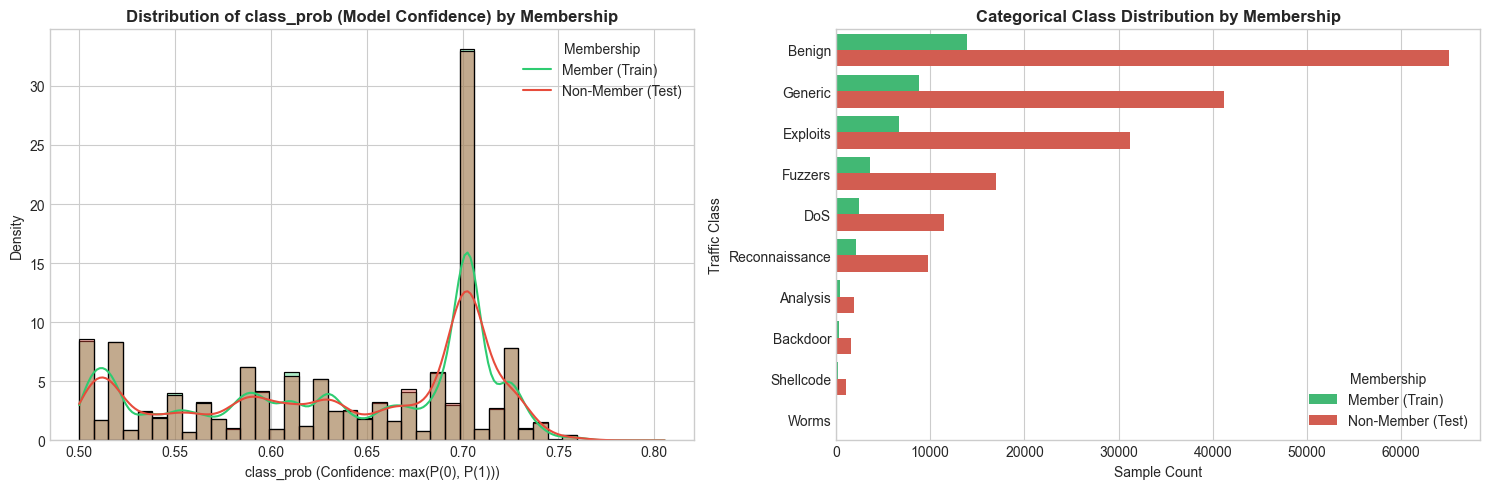

In [6]:
# 1. Compute confidence comparison
member_conf = df_mia[df_mia['is_member'] == 1]['class_prob'].mean()
non_member_conf = df_mia[df_mia['is_member'] == 0]['class_prob'].mean()

print(f"=== Member vs Non-Member Comparison ===")
print(f"Total Members:                         {(df_mia['is_member'] == 1).sum():,}")
print(f"Total Non-Members:                     {(df_mia['is_member'] == 0).sum():,}")
print(f"Mean Confidence on Members (Train):    {member_conf:.4f}")
print(f"Mean Confidence on Non-Members (Test): {non_member_conf:.4f}")
print(f"Confidence Gap:                        {(member_conf - non_member_conf):.4f}")

# 2. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Prediction Confidence Distribution (KDE / Histogram)
sns.histplot(
    data=df_mia,
    x='class_prob',
    hue='is_member',
    bins=40,
    stat='density',
    common_norm=False,
    kde=True,
    palette=['#e74c3c', '#2ecc71'],
    alpha=0.4,
    ax=axes[0]
)
axes[0].set_title("Distribution of class_prob (Model Confidence) by Membership", fontsize=12, fontweight='bold')
axes[0].set_xlabel("class_prob (Confidence: max(P(0), P(1)))")
axes[0].set_ylabel("Density")
axes[0].legend(title="Membership", labels=["Member (Train)", "Non-Member (Test)"])

# Plot 2: Categorical Class Distribution
order = df_mia['predicted_class'].value_counts().index
sns.countplot(
    data=df_mia,
    y='predicted_class',
    hue='is_member',
    order=order,
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[1]
)
axes[1].set_title("Categorical Class Distribution by Membership", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Sample Count")
axes[1].set_ylabel("Traffic Class")
axes[1].legend(title="Membership", labels=["Member (Train)", "Non-Member (Test)"])

plt.tight_layout()
plt.show()

## 6. Stratified 80/20 Train-Test Splitting

We split the unified MIA dataset ($N = 219,022$) into an **80% Training Set** and a **20% Testing Set** for training and evaluating downstream Membership Inference Attack models.
- Stratification is applied jointly across both `is_member` and `predicted_class` to strictly preserve class and membership proportions.
- Reproducibility is guaranteed via `RANDOM_STATE = 42`.

In [7]:
# Perform stratified 80/20 split
mia_train_df, mia_test_df = train_test_split(
    df_mia,
    test_size=0.20,
    stratify=df_mia[['is_member', 'predicted_class']],
    random_state=RANDOM_STATE
)

total_mia_rows = len(df_mia)
train_rows = len(mia_train_df)
test_rows = len(mia_test_df)

split_report = pd.DataFrame({
    'Split': ['MIA Training Set (80%)', 'MIA Testing Set (20%)', 'Total MIA Dataset'],
    'Rows': [train_rows, test_rows, total_mia_rows],
    'Percentage': [train_rows / total_mia_rows * 100, test_rows / total_mia_rows * 100, 100.0],
    'Member Count': [
        (mia_train_df['is_member'] == 1).sum(),
        (mia_test_df['is_member'] == 1).sum(),
        (df_mia['is_member'] == 1).sum()
    ],
    'Member Ratio (%)': [
        (mia_train_df['is_member'] == 1).mean() * 100,
        (mia_test_df['is_member'] == 1).mean() * 100,
        (df_mia['is_member'] == 1).mean() * 100
    ],
    'Attack Count': [
        (mia_train_df['is_attack'] == 1).sum(),
        (mia_test_df['is_attack'] == 1).sum(),
        (df_mia['is_attack'] == 1).sum()
    ],
    'Attack Ratio (%)': [
        (mia_train_df['is_attack'] == 1).mean() * 100,
        (mia_test_df['is_attack'] == 1).mean() * 100,
        (df_mia['is_attack'] == 1).mean() * 100
    ]
})

print("=== MIA Dataset 80/20 Partition Summary ===")
display(split_report.style.format({
    'Rows': '{:,}',
    'Percentage': '{:.2f}%',
    'Member Count': '{:,}',
    'Member Ratio (%)': '{:.2f}%',
    'Attack Count': '{:,}',
    'Attack Ratio (%)': '{:.2f}%'
}))

=== MIA Dataset 80/20 Partition Summary ===


,Split,Rows,Percentage,Member Count,Member Ratio (%),Attack Count,Attack Ratio (%)
0,MIA Training Set (80%),"175,217",80.00%,"144,296",82.35%,"111,977",63.91%
1,MIA Testing Set (20%),"43,805",20.00%,"36,075",82.35%,"27,995",63.91%
2,Total MIA Dataset,"219,022",100.00%,"180,371",82.35%,"139,972",63.91%


## 7. Export Processed MIA Dataset to `datasets/UNSW-NB15_MIA`

Export the partitioned datasets to `datasets/UNSW-NB15_MIA/`:
- `train.csv`: 80% partition ($N = 175,217$)
- `test.csv`: 20% partition ($N = 43,805$)
- `metadata.json`: Complete provenance and feature schema.

In [8]:
# Resolve export destination directory
possible_export_roots = [
    base_dir / '../../datasets',
    base_dir / 'datasets',
    Path(r'd:/Swinburne Courses/Project A/datasets')
]
datasets_root = next((d.resolve() for d in possible_export_roots if d.resolve().exists()), None)
if datasets_root is None:
    raise FileNotFoundError("Could not locate datasets directory.")

export_dir = datasets_root / 'UNSW-NB15_MIA'
export_dir.mkdir(parents=True, exist_ok=True)
print(f"Export directory: {export_dir.resolve()}\n")

# Export CSV files
train_csv_path = export_dir / 'train.csv'
test_csv_path = export_dir / 'test.csv'

print("Exporting train.csv...")
t0 = time.time()
mia_train_df.to_csv(train_csv_path, index=False)
print(f"  - train.csv exported in {time.time()-t0:.2f} s")

print("Exporting test.csv...")
t0 = time.time()
mia_test_df.to_csv(test_csv_path, index=False)
print(f"  - test.csv exported in {time.time()-t0:.2f} s")

# Export metadata.json
metadata_content = {
    "dataset_name": "UNSW-NB15_MIA",
    "description": "Membership Inference Attack dataset derived from UNSW-NB15 and trained AdaBoost IDS model",
    "timestamp": datetime.now().strftime('%Y-%m-%d_%H-%M-%S'),
    "source_ids_model": {
        "model_category": "IDS",
        "model_name": "adaboost",
        "model_path": str(latest_model_dir.relative_to(models_root.parent) if latest_model_dir.is_relative_to(models_root.parent) else latest_model_dir),
        "source_data": "datasets/UNSW-NB15_splited"
    },
    "total_samples": total_mia_rows,
    "train_samples": train_rows,
    "test_samples": test_rows,
    "split_ratio": "80/20 (stratified by is_member and predicted_class)",
    "random_state": RANDOM_STATE,
    "features": [
        {
            "name": "class_prob",
            "type": "float64",
            "description": "Probability of the predicted class from the target IDS model: max(P(Normal), P(Attack))"
        },
        {
            "name": "predicted_class",
            "type": "string",
            "description": "Traffic class label from sample (attack_cat with Normal standardized to Benign, e.g., Benign, DoS, Generic, Exploits, etc.)"
        },
        {
            "name": "is_attack",
            "type": "int64",
            "description": "Ground truth traffic label (0 = Benign/Normal, 1 = Attack)"
        },
        {
            "name": "is_member",
            "type": "int64",
            "description": "Target membership indicator (1 = member from IDS training set, 0 = non-member from IDS test set)"
        }
    ],
    "class_distribution": {
        "is_member": {
            "member_1": int((df_mia['is_member'] == 1).sum()),
            "non_member_0": int((df_mia['is_member'] == 0).sum())
        },
        "is_attack": {
            "attack_1": int((df_mia['is_attack'] == 1).sum()),
            "benign_0": int((df_mia['is_attack'] == 0).sum())
        },
        "predicted_class": df_mia['predicted_class'].value_counts().to_dict()
    }
}

metadata_path = export_dir / 'metadata.json'
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_content, f, indent=4)

print(f"  - metadata.json exported")

# Verification
print("\n=== Verification & File Artifacts ===")
for p in [train_csv_path, test_csv_path, metadata_path]:
    size_mb = p.stat().st_size / (1024 * 1024)
    print(f"  - {p.name:<15} {p.stat().st_size:>10,} bytes ({size_mb:.2f} MB)")

# Quick sanity check on re-loading
re_train = pd.read_csv(train_csv_path, nrows=5)
print(f"\nSanity check (train.csv first 5 rows):")
display(re_train)

Export directory: D:\Swinburne Courses\Project A\datasets\UNSW-NB15_MIA

Exporting train.csv...


  - train.csv exported in 0.26 s
Exporting test.csv...
  - test.csv exported in 0.06 s
  - metadata.json exported

=== Verification & File Artifacts ===
  - train.csv        5,587,329 bytes (5.33 MB)
  - test.csv         1,396,850 bytes (1.33 MB)
  - metadata.json        2,072 bytes (0.00 MB)

Sanity check (train.csv first 5 rows):


,class_prob,predicted_class,is_attack,is_member
0,0.701882,Generic,1,0
1,0.671561,Benign,0,1
2,0.510452,Benign,0,1
3,0.517825,Benign,0,1
4,0.628008,Exploits,1,0
